In [1]:
# 导入数据分析和可视化库

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 读取 FIFA 历史排名数据

url = "https://raw.githubusercontent.com/cnc8/fifa-world-ranking/master/fifa_ranking-2020-12-10.csv"

df = pd.read_csv(url)

# 查看数据结构

print("原始数据形状：", df.shape)
print("\n字段名称：")
print(df.columns.tolist())

display(df.head())

# 筛选亚洲足球联合会球队

afc = df[df["confederation"] == "AFC"].copy()

# 只保留最新一期历史排名

afc["rank_date"] = pd.to_datetime(afc["rank_date"])
latest_date = afc["rank_date"].max()

afc = afc[
    afc["rank_date"] == latest_date
].copy()

# 检查亚洲球队数据

print("\n所选排名日期：", latest_date.date())
print("亚洲球队数量：", len(afc))

display(
    afc[
        ["country_full", "rank", "total_points", "rank_change"]
    ].sort_values("rank").head(10)
)

原始数据形状： (62424, 9)

字段名称：
['id', 'rank', 'country_full', 'country_abrv', 'total_points', 'previous_points', 'rank_change', 'confederation', 'rank_date']


,id,rank,country_full,country_abrv,total_points,previous_points,rank_change,confederation,rank_date
0,43885,104,Swaziland,SWZ,10,0,0,CAF,1992-12-31
1,43972,42,Turkey,TUR,31,0,0,UEFA,1992-12-31
2,43952,43,Northern Ireland,NIR,31,0,0,UEFA,1992-12-31
3,43945,44,Finland,FIN,31,0,0,UEFA,1992-12-31
4,43976,45,Australia,AUS,29,0,0,AFC,1992-12-31



所选排名日期： 2020-12-10
亚洲球队数量： 46


,country_full,rank,total_points,rank_change
62320,Japan,27,1502,0
62322,IR Iran,29,1496,0
62342,Korea Republic,38,1465,0
62334,Australia,41,1457,0
62404,Qatar,58,1391,1
62412,Saudi Arabia,67,1353,0
62414,Iraq,69,1347,0
62419,United Arab Emirates,74,1326,0
62420,China PR,75,1323,0
62398,Syria,76,1313,0


缺失值统计：
total_points       0
previous_points    0
rank_change        0
dtype: int64

重复球队数量：
0

特征统计信息：


,total_points,previous_points,rank_change
count,46.000000,46.000000,46.000000
mean,1136.500000,1136.478261,0.065217
std,188.234458,188.037909,0.326747
min,853.000000,853.000000,0.000000
25%,965.000000,965.000000,0.000000
50%,1121.500000,1121.500000,0.000000
75%,1278.000000,1278.000000,0.000000
max,1502.000000,1502.000000,2.000000


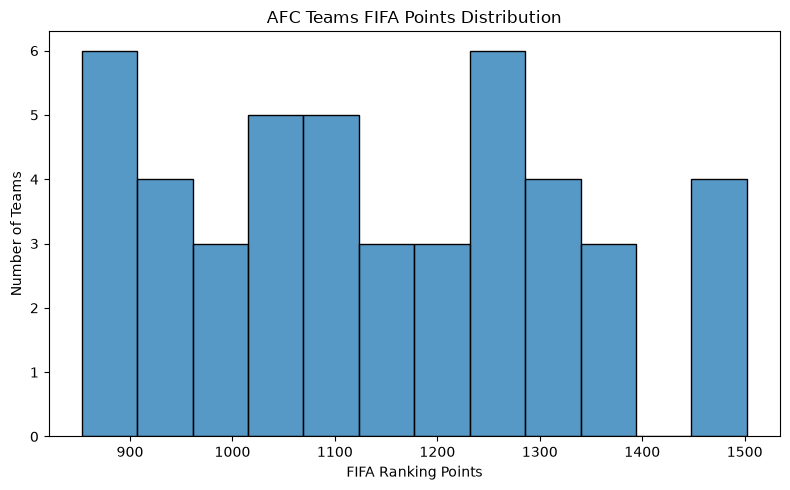

In [2]:
# 选择聚类分析需要的字段

features = [
    "total_points",
    "previous_points",
    "rank_change"
]

# 检查缺失值和重复球队

print("缺失值统计：")
print(afc[features].isnull().sum())

print("\n重复球队数量：")
print(afc["country_full"].duplicated().sum())

print("\n特征统计信息：")
display(afc[features].describe())

# 绘制亚洲球队 FIFA 积分分布

plt.figure(figsize=(8, 5))

sns.histplot(
    data=afc,
    x="total_points",
    bins=12
)

plt.title("AFC Teams FIFA Points Distribution")
plt.xlabel("FIFA Ranking Points")
plt.ylabel("Number of Teams")

plt.tight_layout()

plt.savefig(
    "../results/figures/football_points_distribution.png",
    dpi=300
)

plt.show()

In [3]:
# 导入聚类与评价工具

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# 选择排名积分作为聚类特征

cluster_features = ["total_points"]

X_cluster = afc[cluster_features].copy()

# 标准化数据

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 比较不同算法和聚类数量

cluster_results = []

for k in range(2, 7):

    models = {
        "K-Means": KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ),
        "Hierarchical": AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )
    }

    for name, model in models.items():

        labels = model.fit_predict(X_scaled)

        score = silhouette_score(
            X_scaled,
            labels
        )

        cluster_results.append({
            "Model": name,
            "Clusters": k,
            "Silhouette": score
        })

# 汇总模型比较结果

cluster_comparison = pd.DataFrame(cluster_results)

display(cluster_comparison.round(4))

# 保存模型比较表

cluster_comparison.to_csv(
    "../results/football_cluster_comparison.csv",
    index=False
)

# 查看轮廓系数最高的方案

best_result = cluster_comparison.loc[
    cluster_comparison["Silhouette"].idxmax()
]

print("\n最佳聚类方案：")
print(best_result)

,Model,Clusters,Silhouette
0,K-Means,2,0.6187
1,Hierarchical,2,0.5877
2,K-Means,3,0.5997
3,Hierarchical,3,0.5997
4,K-Means,4,0.6153
5,Hierarchical,4,0.6168
6,K-Means,5,0.6309
7,Hierarchical,5,0.6137
8,K-Means,6,0.6495
9,Hierarchical,6,0.6313



最佳聚类方案：
Model          K-Means
Clusters             6
Silhouette    0.649453
Name: 8, dtype: object


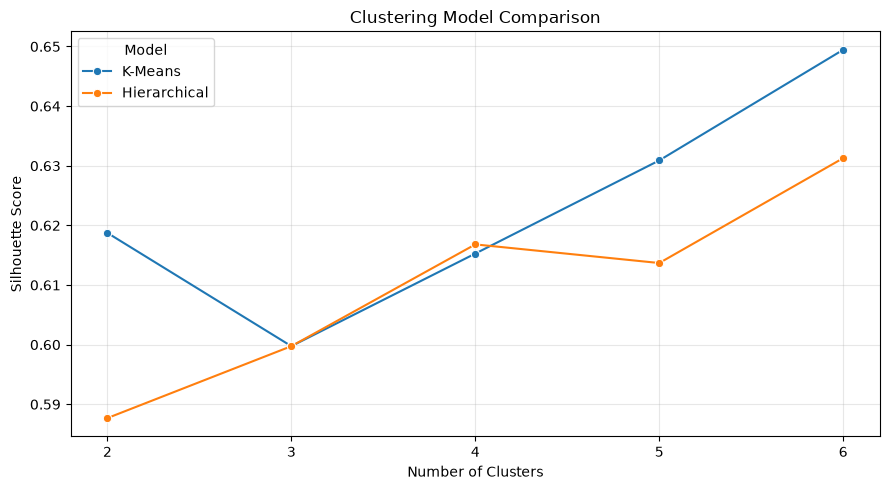

In [4]:
# 比较不同聚类数量下的轮廓系数

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=cluster_comparison,
    x="Clusters",
    y="Silhouette",
    hue="Model",
    marker="o"
)

plt.title("Clustering Model Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.tight_layout()

# 保存模型对比图

plt.savefig(
    "../results/figures/football_cluster_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Teams,Mean_Points,Min_Points,Max_Points
Group,,,,
Group 1,4,1480.00,1457,1502
Group 2,7,1336.57,1303,1391
Group 3,6,1254.33,1238,1283
Group 4,6,1169.67,1136,1204
Group 5,10,1061.90,1020,1107
Group 6,13,910.77,853,968


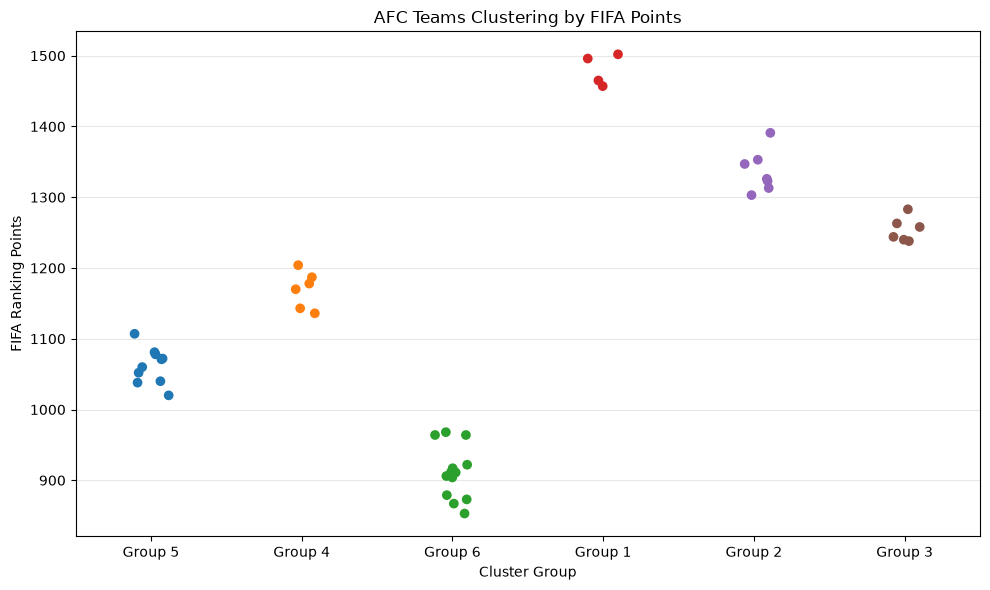

聚类结果保存成功


In [5]:
# 读取最佳模型参数

best_model_name = best_result["Model"]
best_k = int(best_result["Clusters"])

# 重新训练最佳聚类模型

if best_model_name == "K-Means":

    best_model = KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=10
    )

else:

    best_model = AgglomerativeClustering(
        n_clusters=best_k,
        linkage="ward"
    )

# 获取聚类标签

afc_result = afc.copy()

afc_result["Cluster"] = best_model.fit_predict(
    X_scaled
)

# 按各簇平均积分排序

cluster_order = (
    afc_result.groupby("Cluster")["total_points"]
    .mean()
    .sort_values(ascending=False)
    .index
)

cluster_names = {
    cluster: f"Group {i + 1}"
    for i, cluster in enumerate(cluster_order)
}

afc_result["Group"] = afc_result["Cluster"].map(
    cluster_names
)

# 查看各组的积分和球队数量

cluster_summary = (
    afc_result.groupby("Group")
    .agg(
        Teams=("country_full", "count"),
        Mean_Points=("total_points", "mean"),
        Min_Points=("total_points", "min"),
        Max_Points=("total_points", "max")
    )
    .sort_index()
)

display(cluster_summary.round(2))

# 绘制球队积分分组图

plt.figure(figsize=(10, 6))

sns.stripplot(
    data=afc_result,
    x="Group",
    y="total_points",
    hue="Group",
    jitter=0.12,
    size=7,
    legend=False
)

plt.title("AFC Teams Clustering by FIFA Points")
plt.xlabel("Cluster Group")
plt.ylabel("FIFA Ranking Points")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# 保存聚类结果图

plt.savefig(
    "../results/figures/football_cluster_groups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 保存球队分组结果

afc_result[
    ["country_full", "rank", "total_points", "Group"]
].sort_values(
    "total_points",
    ascending=False
).to_csv(
    "../results/football_team_clusters.csv",
    index=False
)

print("聚类结果保存成功")